# Importing

## Import Library

# 📊 Dataset Information

**Note:** The dataset for this project is **not included in this repository** to keep the repository lightweight.  

You can download the dataset from **Kaggle** using the link below:  

[Download The Retails Store Sales Dataset](https://www.kaggle.com/datasets/hassanjameelahmed/store-sales)  

Please make sure to place the downloaded CSV file in the same directory as this notebook before running any code.

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

/kaggle/input/datasets/hassanjameelahmed/store-sales/store_sales.csv


## Import CSV And convert to DataFrame

In [19]:
df = pd.read_csv('store_sales.csv')

# Preprocessing

## Frist five row

In [20]:
df.head()

,CustomerID,Age,Gender,Category,ItemPurchased,Amount,Season,PaymentMethod,ItemRating,DiscountApplied(%),PreviousPurchases
0,1,58,Female,Accessories,Handbag,115.50,Autumn,Card,3.5,18,4
1,2,40,Male,Mens Clothing,Shirt,103.43,Spring,Card,4.1,13,4
2,3,66,Female,Sports,Football,35.45,Spring,Card,3.3,11,3
3,4,39,Female,Accessories,Handbag,153.31,Spring,Card,4.4,13,4
4,5,23,Female,Home,Curtains,151.43,Winter,Card,4.1,20,10


## last Five row

In [21]:
df.tail()

,CustomerID,Age,Gender,Category,ItemPurchased,Amount,Season,PaymentMethod,ItemRating,DiscountApplied(%),PreviousPurchases
4995,4996,44,Female,Accessories,Sunglasses,172.64,Winter,Card,3.6,20,5
4996,4997,59,Male,Groceries,Beverages,54.00,Spring,Cash on Delivery,3.8,14,2
4997,4998,41,Female,Accessories,Handbag,159.33,Autumn,Card,4.3,26,8
4998,4999,63,Female,Womens Clothing,Skirt,173.82,Autumn,Card,4.8,26,8
4999,5000,41,Female,Footwear,Sandals,55.39,Autumn,Cash on Delivery,4.1,19,7


## Shape of our dataset

In [22]:
df.shape

(5000, 11)

## List out all columns

In [23]:
df.columns

Index(['CustomerID', 'Age', 'Gender', 'Category', 'ItemPurchased', 'Amount',
       'Season', 'PaymentMethod', 'ItemRating', 'DiscountApplied(%)',
       'PreviousPurchases'],
      dtype='object')

## Datatype of each columns

In [24]:
df.dtypes

CustomerID              int64
Age                     int64
Gender                 object
Category               object
ItemPurchased          object
Amount                float64
Season                 object
PaymentMethod          object
ItemRating            float64
DiscountApplied(%)      int64
PreviousPurchases       int64
dtype: object

## Information of all Columns

In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   CustomerID          5000 non-null   int64  
 1   Age                 5000 non-null   int64  
 2   Gender              5000 non-null   object 
 3   Category            5000 non-null   object 
 4   ItemPurchased       5000 non-null   object 
 5   Amount              5000 non-null   float64
 6   Season              5000 non-null   object 
 7   PaymentMethod       5000 non-null   object 
 8   ItemRating          5000 non-null   float64
 9   DiscountApplied(%)  5000 non-null   int64  
 10  PreviousPurchases   5000 non-null   int64  
dtypes: float64(2), int64(4), object(5)
memory usage: 429.8+ KB


## Check Null Value

In [26]:
df.isnull().sum()

CustomerID            0
Age                   0
Gender                0
Category              0
ItemPurchased         0
Amount                0
Season                0
PaymentMethod         0
ItemRating            0
DiscountApplied(%)    0
PreviousPurchases     0
dtype: int64

## Check Dupicate Value

In [27]:
df.duplicated().sum()

np.int64(0)

## Summary

In [28]:
df.describe()

,CustomerID,Age,Amount,ItemRating,DiscountApplied(%),PreviousPurchases
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,2500.500000,45.224800,285.090522,3.784160,14.983600,5.008800
std,1443.520003,14.564995,551.454382,0.681796,5.988063,2.194285
min,1.000000,20.000000,5.080000,1.100000,0.000000,0.000000
25%,1250.750000,33.000000,70.547500,3.300000,11.000000,3.000000
50%,2500.500000,45.000000,122.485000,3.800000,15.000000,5.000000
75%,3750.250000,58.000000,184.535000,4.300000,19.000000,6.000000
max,5000.000000,70.000000,2997.940000,5.000000,36.000000,13.000000


# EDA

In [29]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

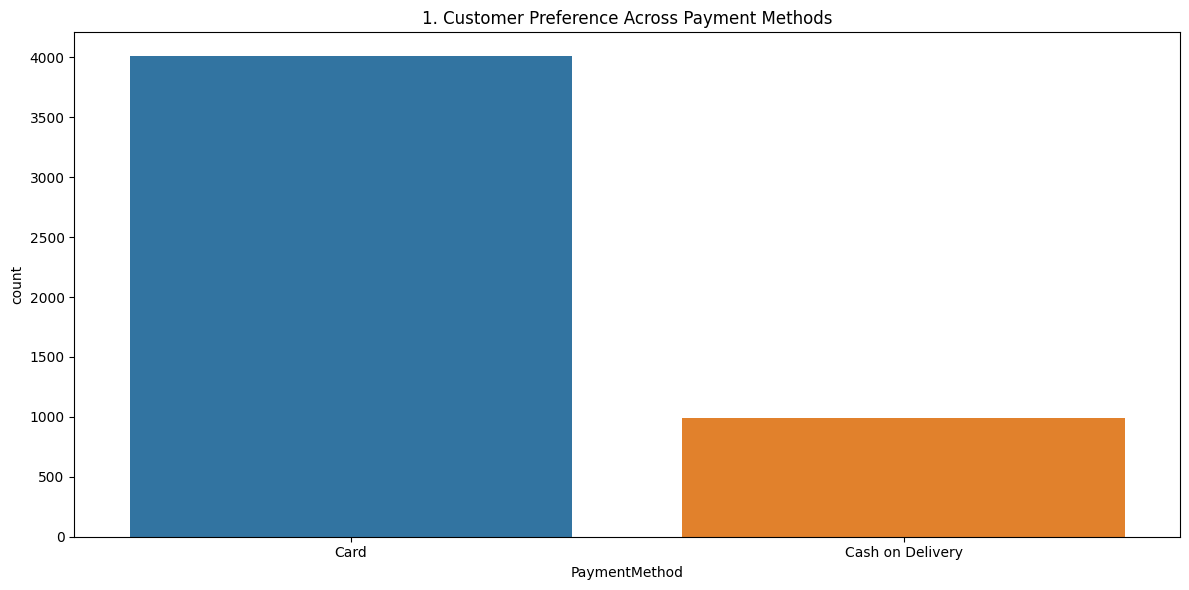

In [30]:
fig = plt.figure(figsize=(12,6))
sns.countplot(data=df, x='PaymentMethod', hue='PaymentMethod')
plt.title(f'{plot_no}. Customer Preference Across Payment Methods')
show_fig()
plot_no += 1

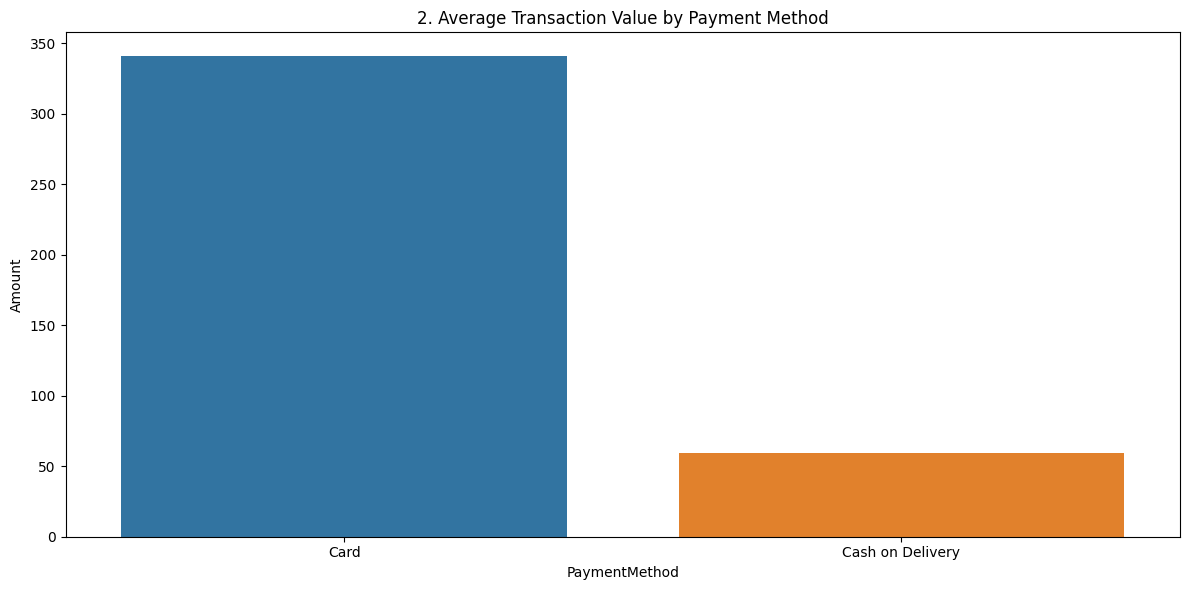

In [31]:
fig = plt.figure(figsize=(12,6))
sns.barplot(data=df, x='PaymentMethod', y='Amount', hue='PaymentMethod', estimator='mean', errorbar=None)
plt.title(f'{plot_no}. Average Transaction Value by Payment Method')
show_fig()
plot_no += 1

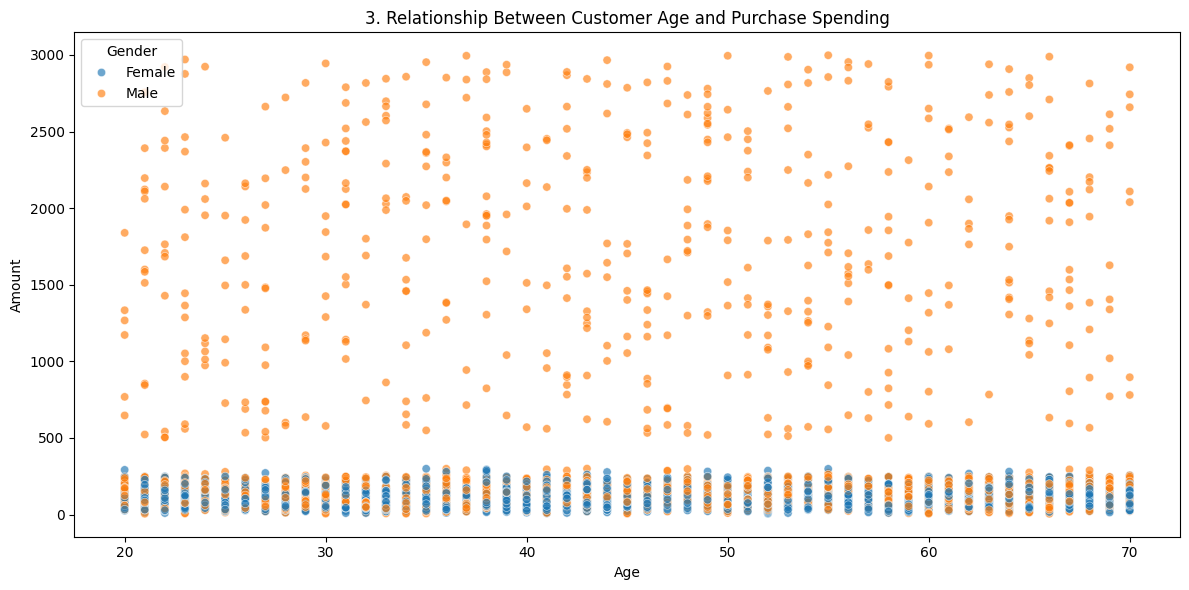

In [32]:
fig = plt.figure(figsize=(12,6))
sns.scatterplot(data=df, x='Age', y='Amount', hue='Gender', alpha=0.65)
plt.title(f'{plot_no}. Relationship Between Customer Age and Purchase Spending')
show_fig()
plot_no += 1

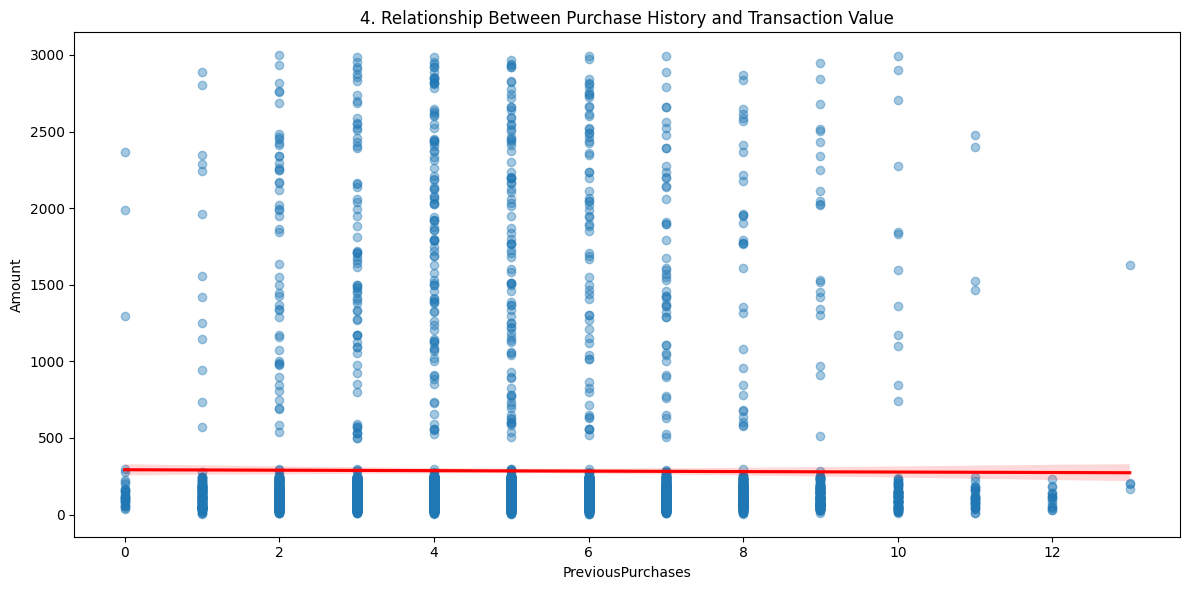

In [33]:
fig = plt.figure(figsize=(12,6))
sns.regplot(data=df, x='PreviousPurchases', y='Amount', scatter_kws={'alpha':0.4}, line_kws={'color':'red'})
plt.title(f'{plot_no}. Relationship Between Purchase History and Transaction Value')
show_fig()
plot_no += 1

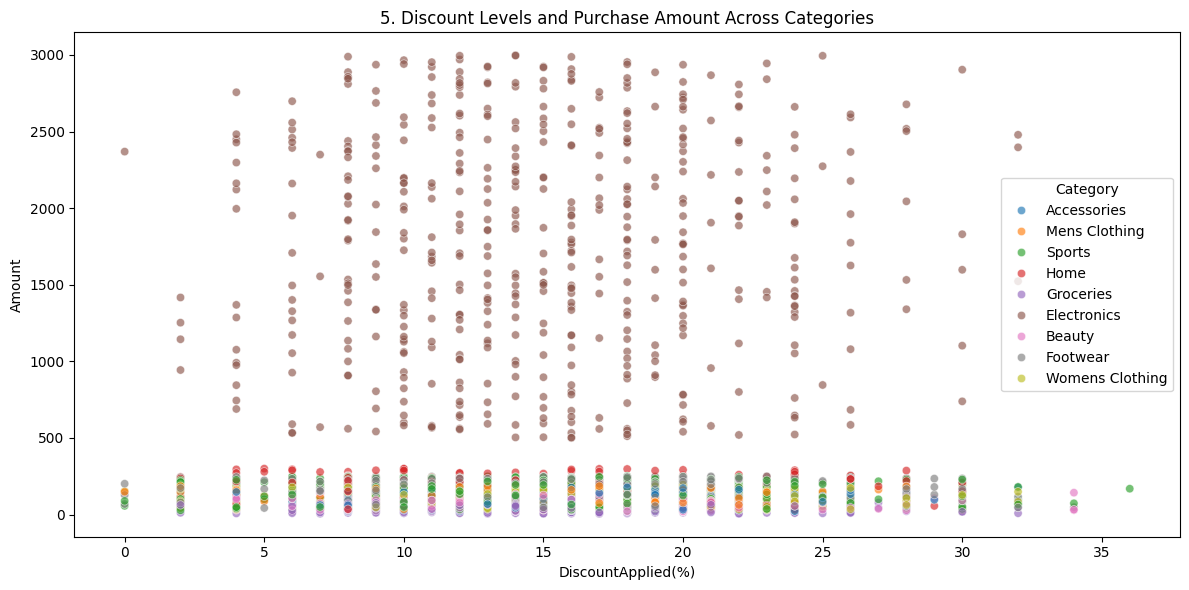

In [34]:
fig = plt.figure(figsize=(12,6))
sns.scatterplot(data=df, x='DiscountApplied(%)', y='Amount', hue='Category', alpha=0.65)
plt.title(f'{plot_no}. Discount Levels and Purchase Amount Across Categories')
show_fig()
plot_no += 1

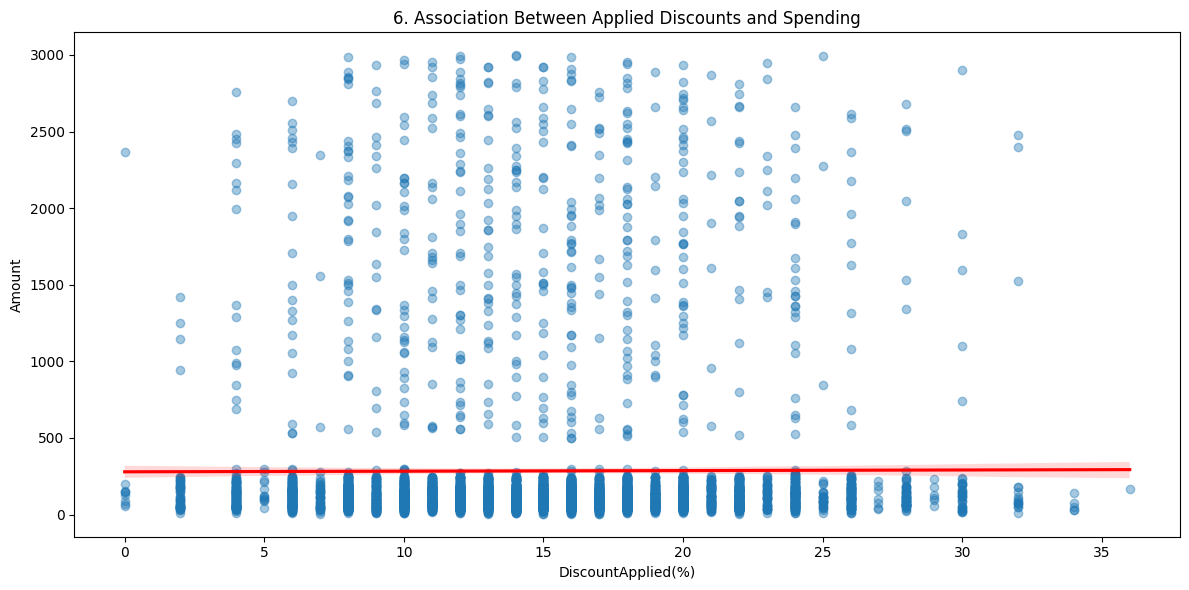

In [35]:
fig = plt.figure(figsize=(12,6))
sns.regplot(data=df, x='DiscountApplied(%)', y='Amount', scatter_kws={'alpha':0.4}, line_kws={'color':'red'})
plt.title(f'{plot_no}. Association Between Applied Discounts and Spending')
show_fig()
plot_no += 1

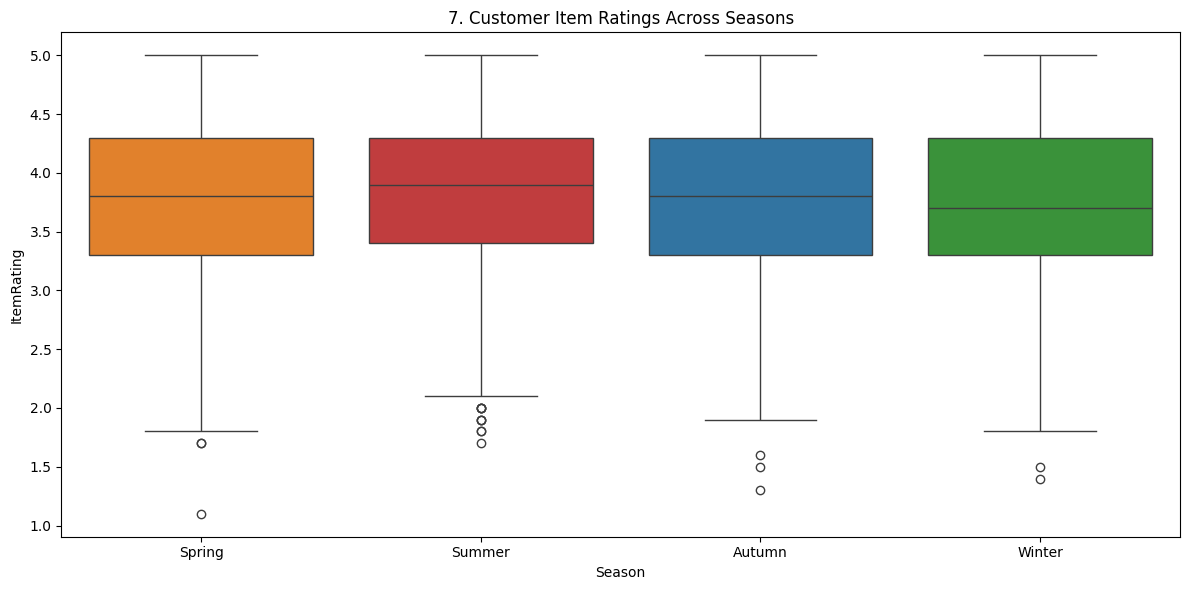

In [36]:
fig = plt.figure(figsize=(12,6))
sns.boxplot(data=df, x='Season', y='ItemRating', hue='Season', order=['Spring','Summer','Autumn','Winter'])
plt.title(f'{plot_no}. Customer Item Ratings Across Seasons')
show_fig()
plot_no += 1

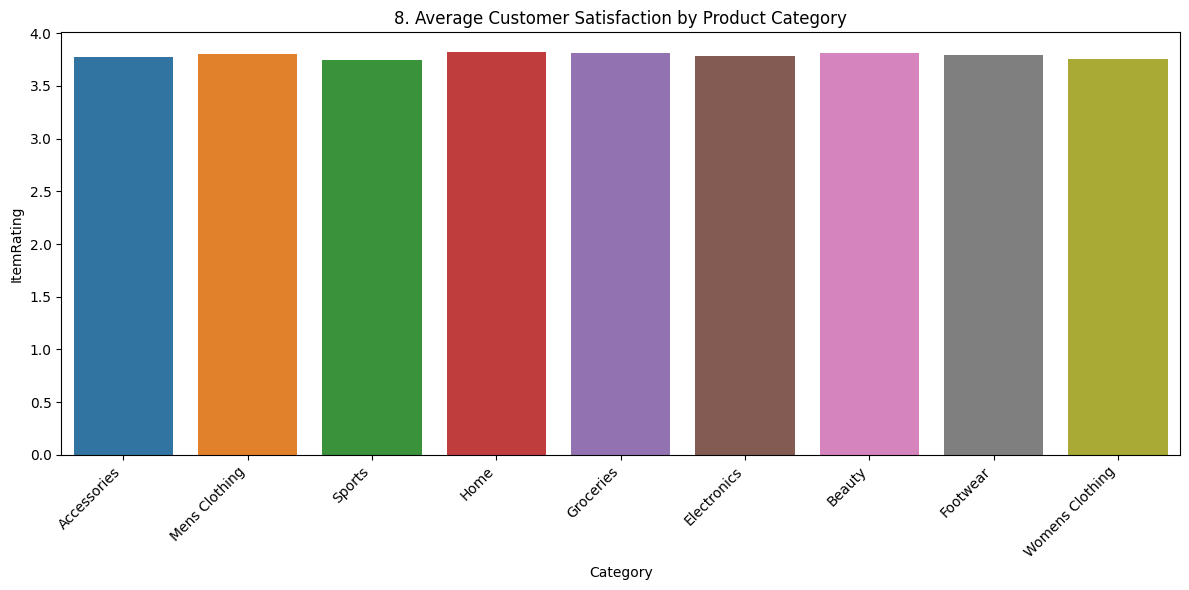

In [37]:
fig = plt.figure(figsize=(12,6))
sns.barplot(data=df, x='Category', y='ItemRating', hue='Category', estimator='mean', errorbar=None)
plt.xticks(rotation=45, ha='right')
plt.title(f'{plot_no}. Average Customer Satisfaction by Product Category')
show_fig()
plot_no += 1

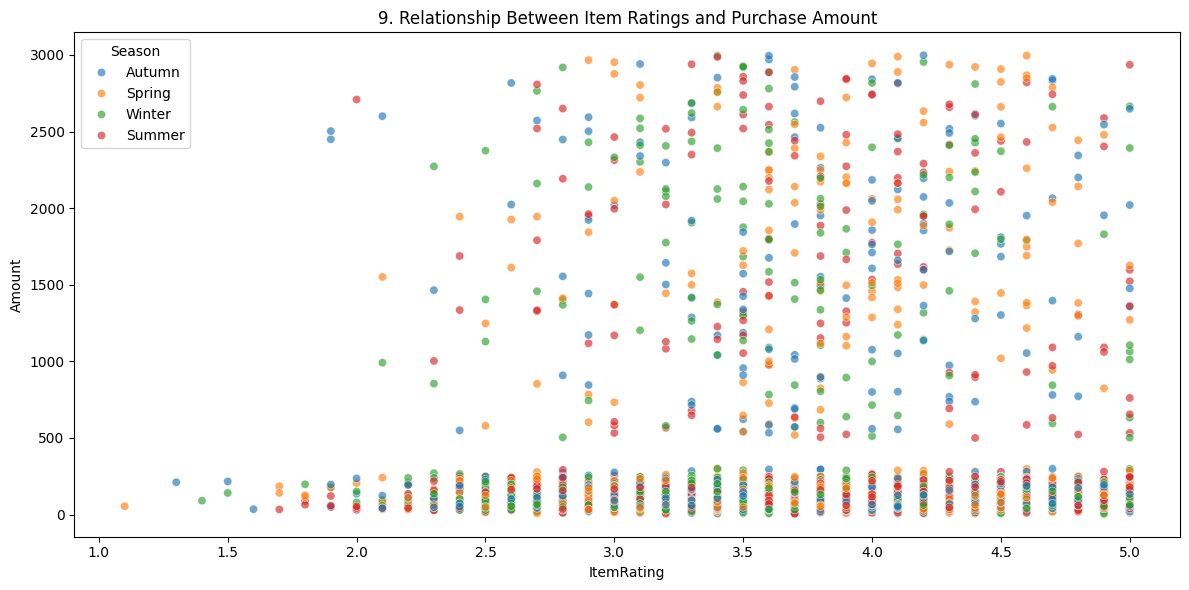

In [38]:
fig = plt.figure(figsize=(12,6))
sns.scatterplot(data=df, x='ItemRating', y='Amount', hue='Season', alpha=0.65)
plt.title(f'{plot_no}. Relationship Between Item Ratings and Purchase Amount')
show_fig()
plot_no += 1

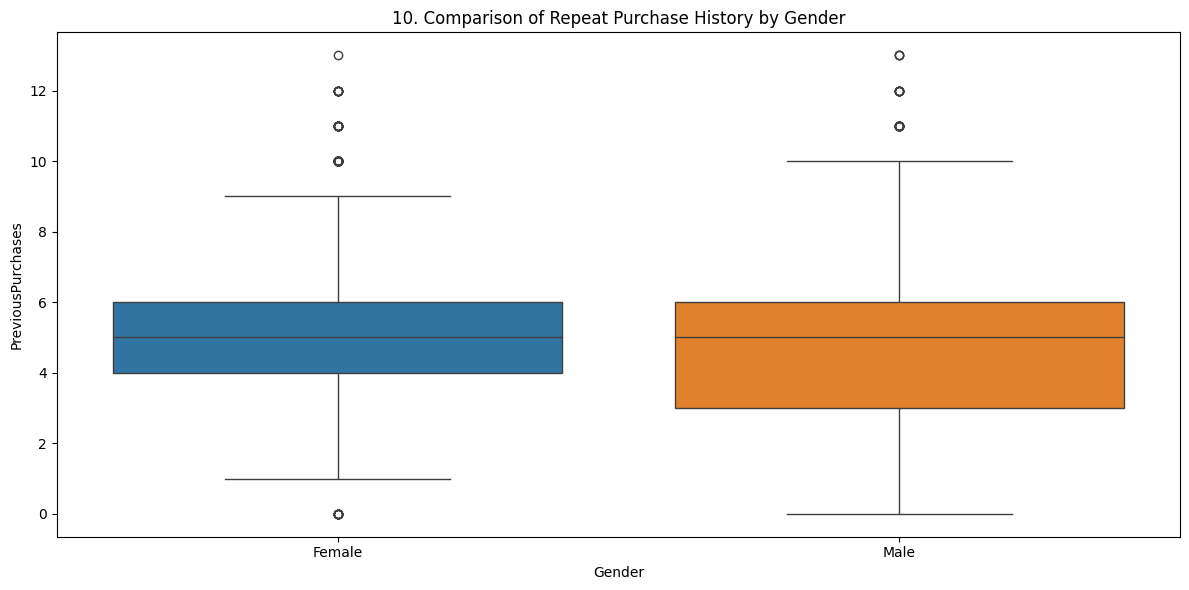

In [39]:
fig = plt.figure(figsize=(12,6))
sns.boxplot(data=df, x='Gender', y='PreviousPurchases', hue='Gender')
plt.title(f'{plot_no}. Comparison of Repeat Purchase History by Gender')
show_fig()
plot_no += 1

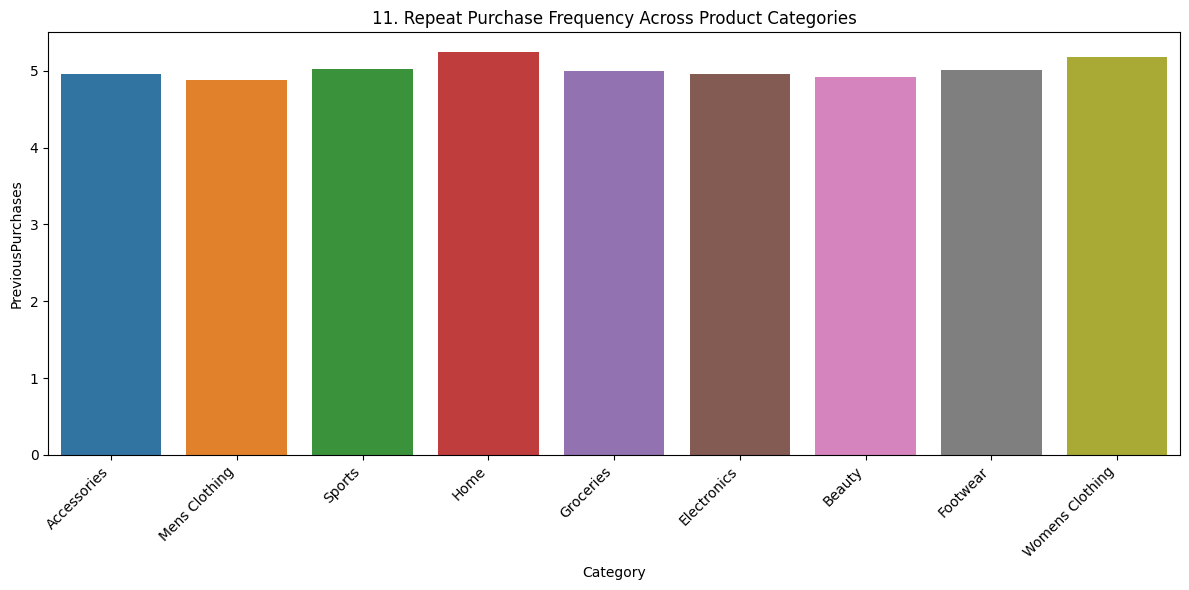

In [40]:
fig = plt.figure(figsize=(12,6))
sns.barplot(data=df, x='Category', y='PreviousPurchases', hue='Category', estimator='mean', errorbar=None)
plt.xticks(rotation=45, ha='right')
plt.title(f'{plot_no}. Repeat Purchase Frequency Across Product Categories')
show_fig()
plot_no += 1

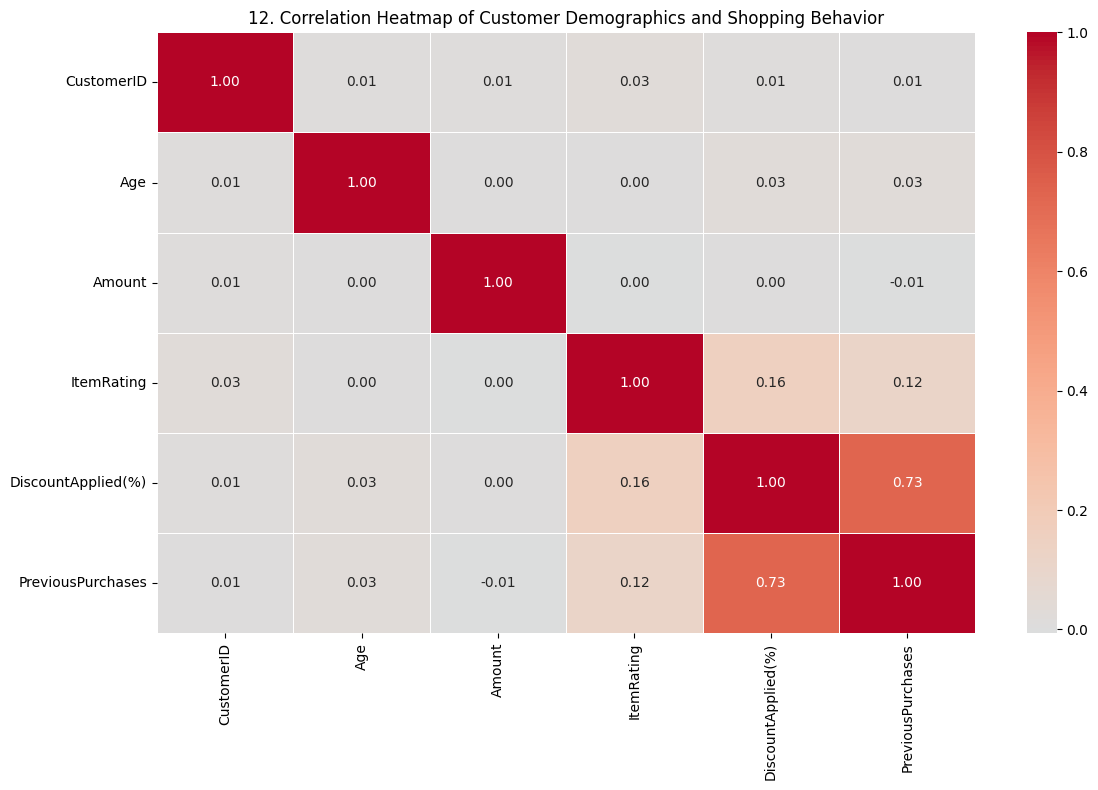

In [41]:
fig = plt.figure(figsize=(12,8))
corr = df.select_dtypes(include='number').corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, center=0)
plt.title(f'{plot_no}. Correlation Heatmap of Customer Demographics and Shopping Behavior')
show_fig()
plot_no += 1